# Problem Setup
Here, we will fit a two-dimensional function using Unet and use convolution for the derivation of this two-dimensional function and compare it to the analytic form.

### U-net structure
![Unet](./Fig/Unet.png)

# Libraries

In [1]:
from Lib.Unet import *
from Lib import myFCNGrad as mg

MPS is available, running on MPS


# Tunning Parameters

In [2]:
steps = 5000
lr = 1e-3

xmin = 0
ymin = 0

Length = 1
Height = 1

# ------------------------------ define domain and collocation points -------------------------------
resolution = 128

KernelSize = 5
pad_size = KernelSize//2

# Functions

In [3]:
def f(x, y):
    u0 = np.sin(np.pi * x) * np.sin(4 * np.pi * y) * np.cos(2 * np.pi * x) * np.cos(np.pi * y / 2)
    return u0
def df(x, y):
    du0dx = np.pi*np.sin(4*np.pi*y)*np.cos(np.pi*y/2)*(np.cos(np.pi*x)*np.cos(2*np.pi*x)-2*np.sin(np.pi*x)*np.sin(2*np.pi*x))
    du0dy = 1/2*np.pi*np.sin(np.pi*x)*np.cos(2*np.pi*x)*(8*np.cos(1/2*np.pi*y)*np.cos(4*np.pi*y)-np.sin(1/2*np.pi*y)*np.sin(4*np.pi*y))
    return du0dx, du0dy

def pad_xy(input,size=2):
    # Padding x axis due to periodic boundary condition
    # shape: [t, c, h, w]
    input = torch.cat((input[:, :, :, -size:], input, input[:, :, :, 0:size]), dim=3)

    # Padding y axis due to periodic boundary condition
    # shape: [t, c, h, w]
    output = torch.cat((input[:, :, -size:, :], input, input[:, :, 0:size, :]), dim=2)

    return output

# Generate data

In [4]:
x = np.linspace(0,1,resolution)
y = np.linspace(0,1,resolution)
xGrid, yGrid = np.meshgrid(x, y)

f = f(xGrid, yGrid)
dfx, dfy = df(xGrid, yGrid)

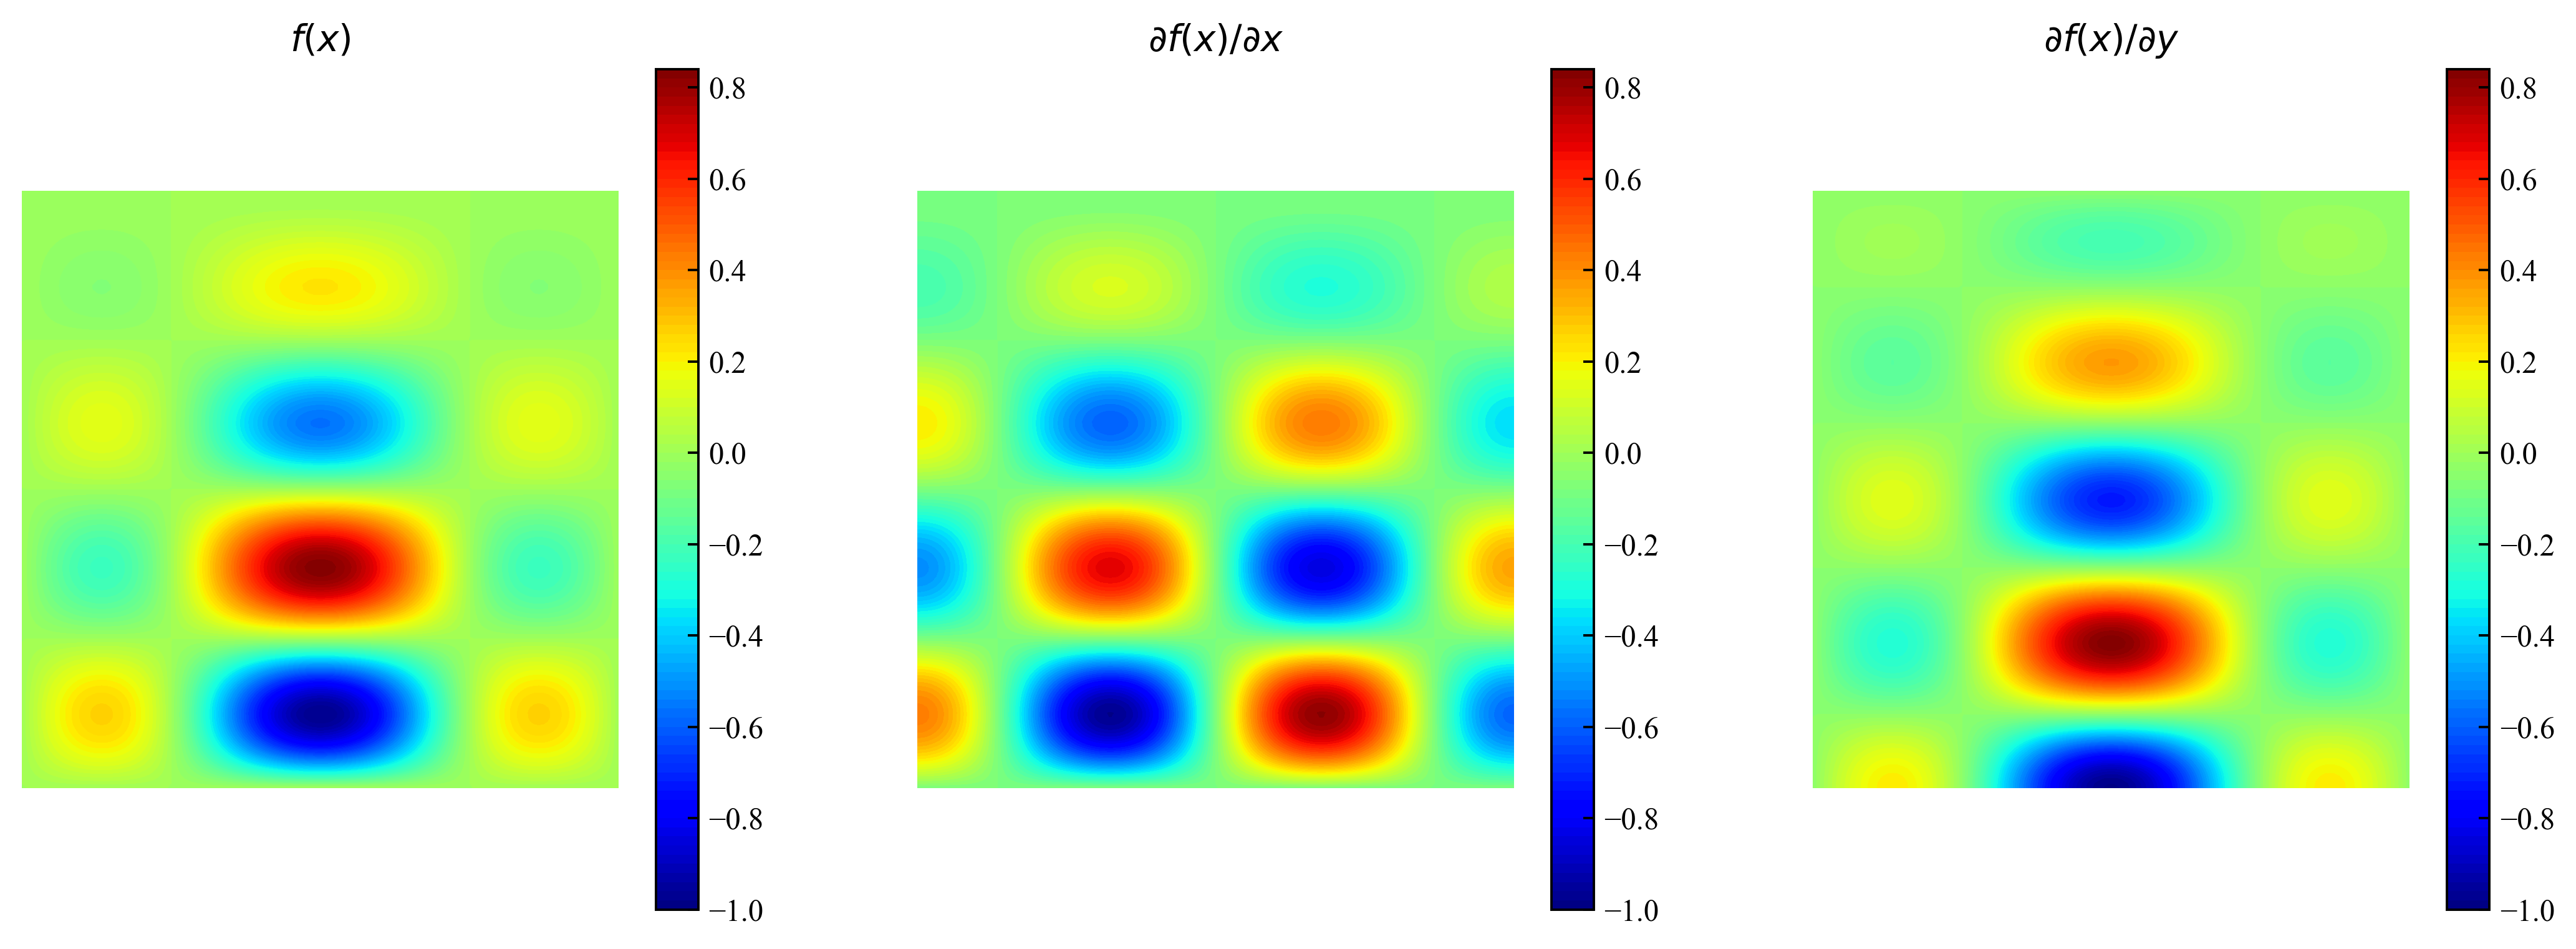

In [5]:
fig, axes = plt.subplots(nrows=1, ncols=3,figsize=(15,5))
ax1 = axes[0].contourf(xGrid, yGrid, f, levels=100, cmap=plt.get_cmap('jet'))
axes[0].axis('equal')
axes[0].axis('off')
axes[0].set_title(r'$f(x)$')
cbar1=fig.colorbar(ax1, ax=axes[0])

ax2 = axes[1].contourf(xGrid, yGrid, dfx, levels=100, cmap=plt.get_cmap('jet'))
axes[1].axis('equal')
axes[1].axis('off')
axes[1].set_title(r'$\partial f(x)/\partial x$')
cbar1=fig.colorbar(ax1, ax=axes[1])

ax3 = axes[2].contourf(xGrid, yGrid, dfy, levels=100, cmap=plt.get_cmap('jet'))
axes[2].axis('equal')
axes[2].axis('off')
axes[2].set_title(r'$\partial f(x)/\partial y$')
cbar1=fig.colorbar(ax1, ax=axes[2])

# Defining the inputs to a function

Since Unet establishes an image-to-image link. Here we assume that the input image is f(x)/2.So here we establish the Unet relation from f->2f.

Here the dimension of the input image is [1,1,128,128] which is required for convolution where the dimension of the input is [N,C,W,H].
Where N represents the number of images, C represents the number of channels in the image, W,H represents the height and width (number of pixels) of the image respectively


In [6]:
input_img = f/2
input_img = torch.from_numpy(input_img.reshape(1, 1, resolution, resolution)).float().to(dev)
print(input_img.shape)

output_img = torch.from_numpy(f.reshape(1, 1, resolution, resolution)).float().to(dev)

torch.Size([1, 1, 128, 128])


# Defining the Network

Where in_channels denotes the features of the input image, here we take a grayscale image as input, so the number of in_channels is 1, if the image is an RGB image, then the number of in_channels is 3; num_classes denotes the number of output images, here it is considered as one output.

In [7]:
model = UNet5(in_channels=1, num_classes=1,channels = [32, 64, 64, 64, 64]).to(dev)

# Train Neural Network

In [8]:
optimizer = torch.optim.Adam(model.parameters(),lr=lr)

In [9]:
start_time = time.time()
it_time = time.time()
for i in range(steps):
    optimizer.zero_grad()
    yh = model(input_img)
    loss = torch.mean(torch.square(yh-output_img)) # use mean squared error
    loss.backward()
    optimizer.step()
    if i%(steps/10)==0:
      print('Iter: %d  Loss: %.5e  Time: %.3e'
                    % (i, loss.item(), time.time() - it_time))
      torch.save(model.state_dict(), './output/Case8/model.pt')
      it_time = time.time()

Iter: 0  Loss: 7.57612e-01  Time: 9.885e-01
Iter: 500  Loss: 1.72138e-05  Time: 2.849e+01
Iter: 1000  Loss: 4.36535e-05  Time: 2.819e+01
Iter: 1500  Loss: 3.16146e-06  Time: 2.766e+01
Iter: 2000  Loss: 1.89891e-06  Time: 2.765e+01
Iter: 2500  Loss: 1.24425e-06  Time: 2.760e+01
Iter: 3000  Loss: 9.26020e-07  Time: 2.770e+01
Iter: 3500  Loss: 9.55917e-07  Time: 2.760e+01
Iter: 4000  Loss: 5.11824e-07  Time: 2.834e+01
Iter: 4500  Loss: 5.66313e-07  Time: 2.917e+01


# Test Model

In [10]:
output_y = model(input_img).detach().cpu().numpy()
output_y = output_y.reshape(resolution, resolution)

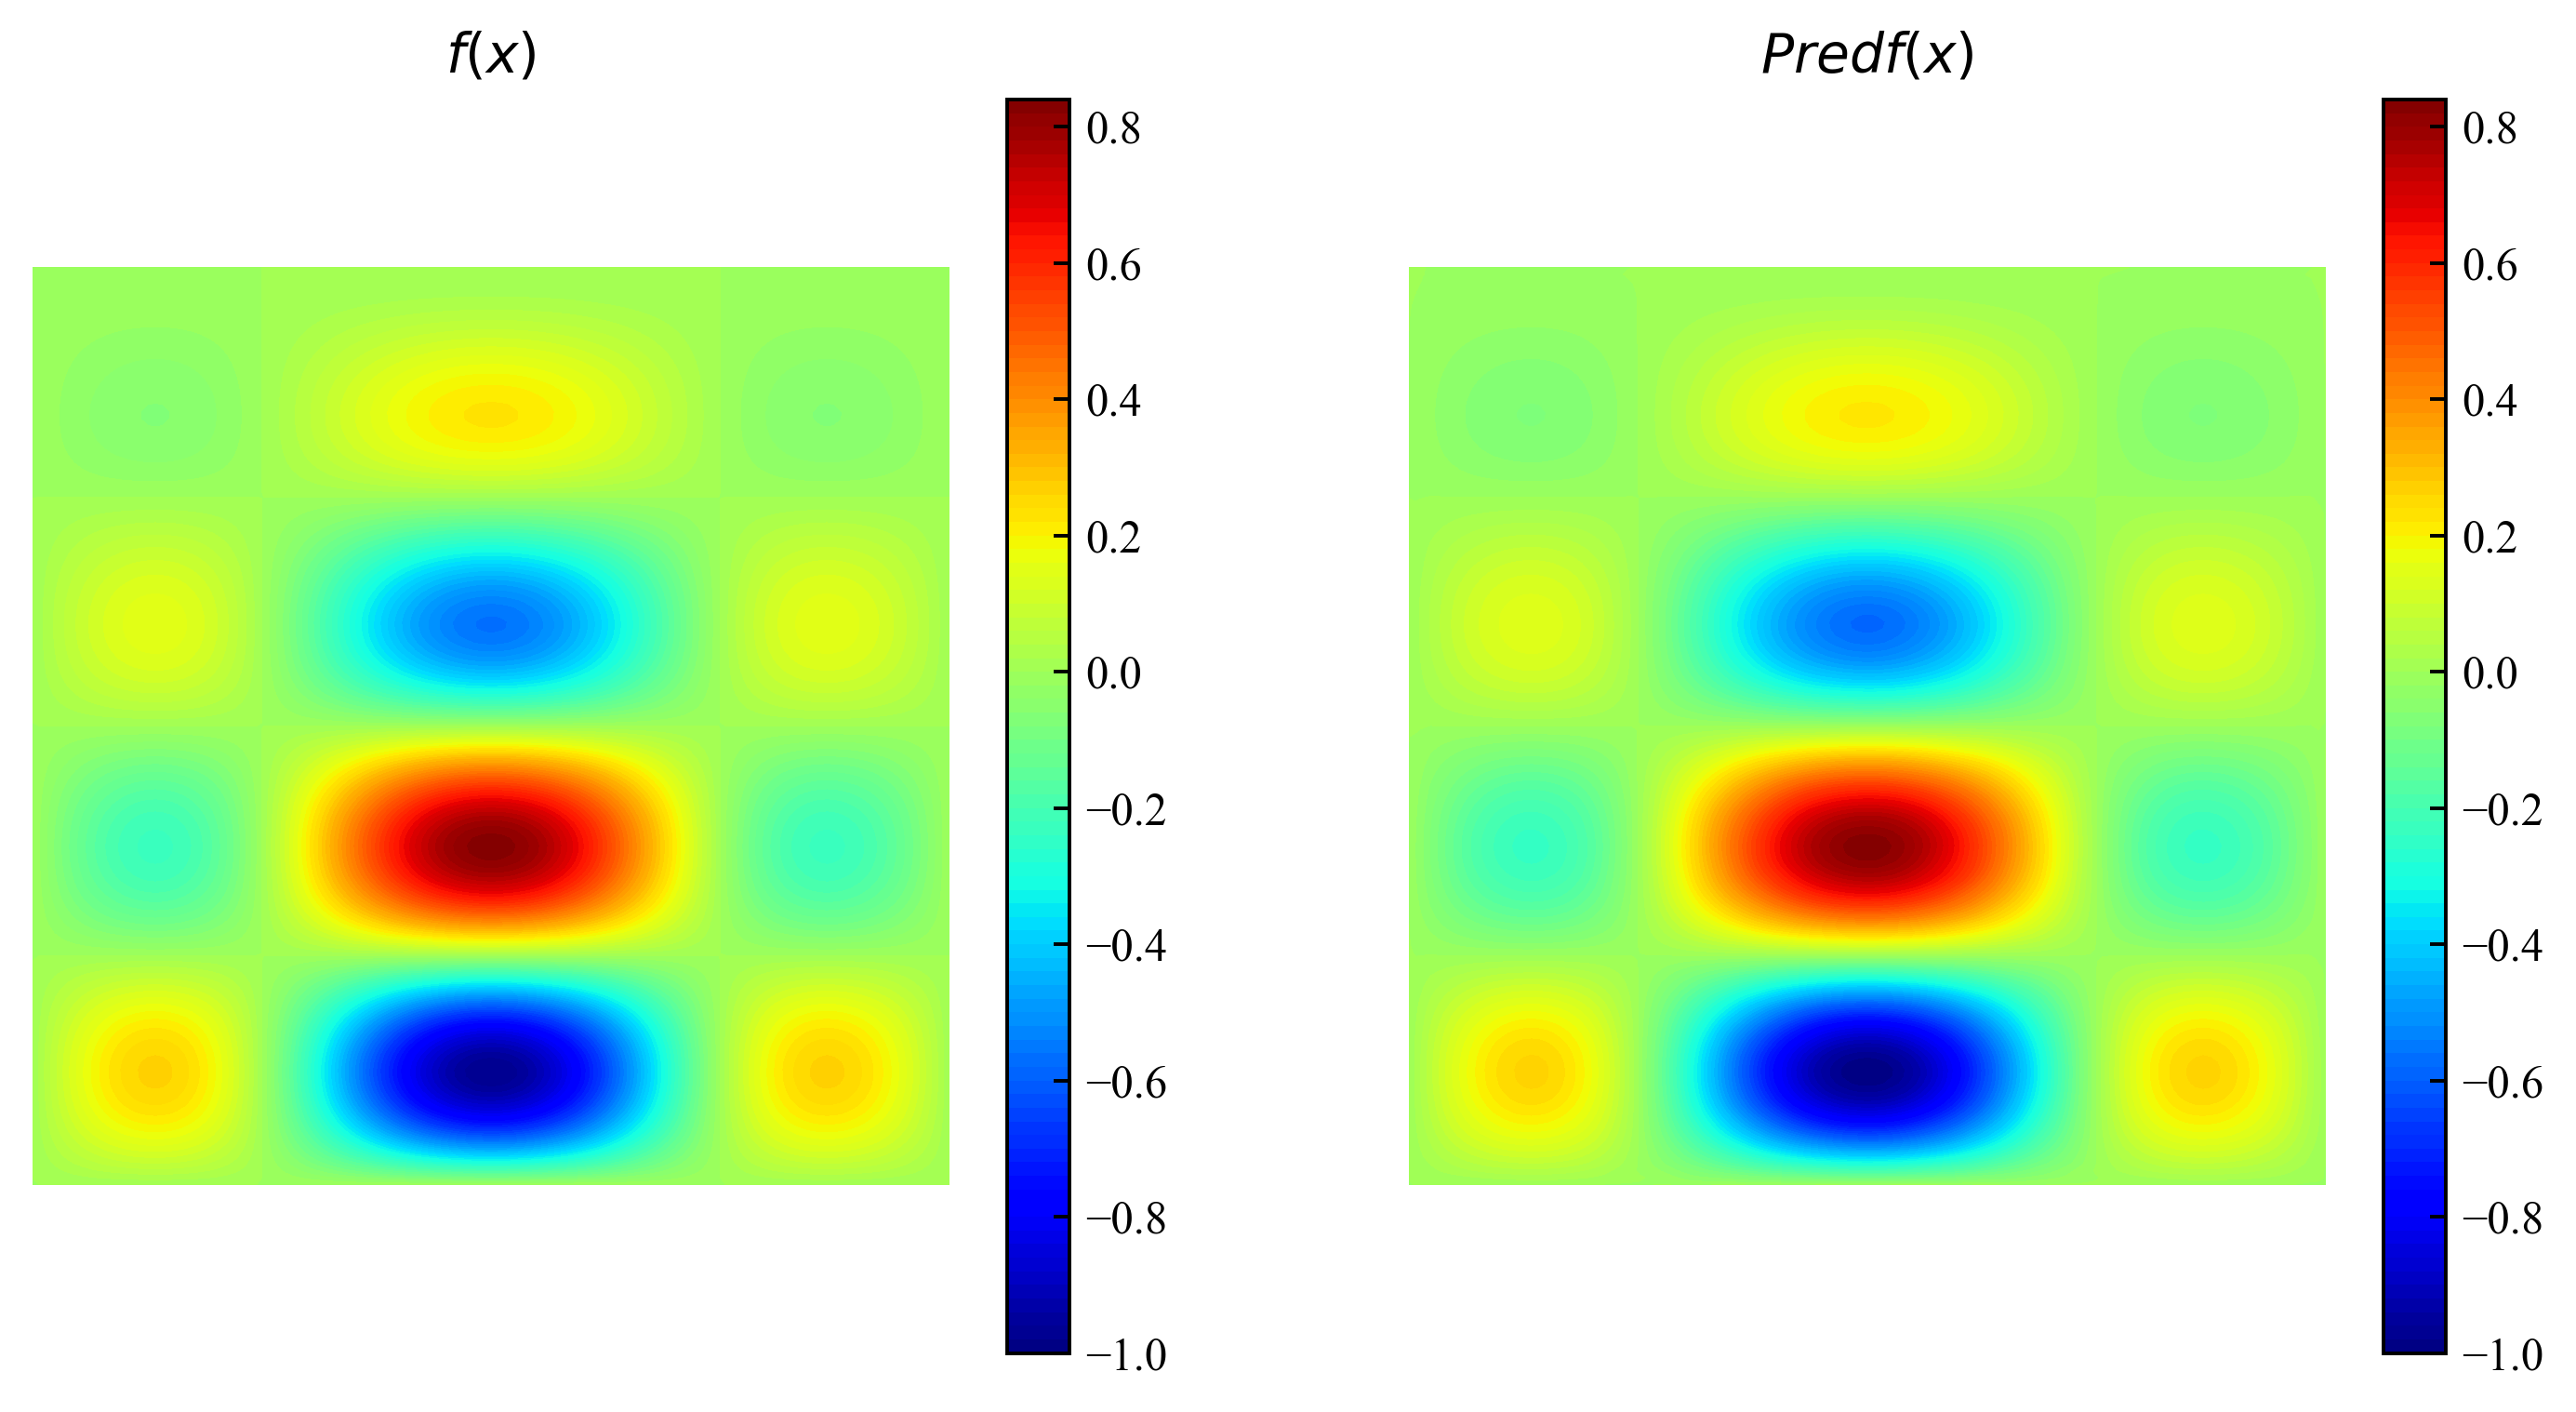

In [11]:
fig, axes = plt.subplots(nrows=1, ncols=2,figsize=(10,5))
ax1 = axes[0].contourf(xGrid, yGrid, f, levels=100, cmap=plt.get_cmap('jet'))
axes[0].axis('equal')
axes[0].axis('off')
axes[0].set_title(r'$f(x)$')
cbar1=fig.colorbar(ax1, ax=axes[0])

ax2 = axes[1].contourf(xGrid, yGrid, output_y, levels=100, cmap=plt.get_cmap('jet'))
axes[1].axis('equal')
axes[1].axis('off')
axes[1].set_title(r'$Pred f(x)$')
cbar1=fig.colorbar(ax1, ax=axes[1])

# Using convolution to obtain functional derivatives

In [12]:
grad = mg.Derivative(dx=1/resolution, dy=1/resolution, KernelSize=KernelSize)

Since the derivation is done using the convolution method, the convolution shrinks the picture, so the original function needs to be padded appropriately. In PDNN, proper padding can be done based on the boundary conditions.

In [13]:
output_img = pad_xy(output_img, size=pad_size)
print(output_img.shape)

torch.Size([1, 1, 132, 132])


In [14]:
f_x = grad.dx(output_img[0:1, 0:1, :, :])
f_y = grad.dy(output_img[0:1, 0:1, :, :])
print(f_x.shape)
print(f_y.shape)

f_x = f_x.reshape(resolution, resolution).detach().cpu().numpy()
f_y = f_y.reshape(resolution, resolution).detach().cpu().numpy()

torch.Size([1, 1, 128, 128])
torch.Size([1, 1, 128, 128])


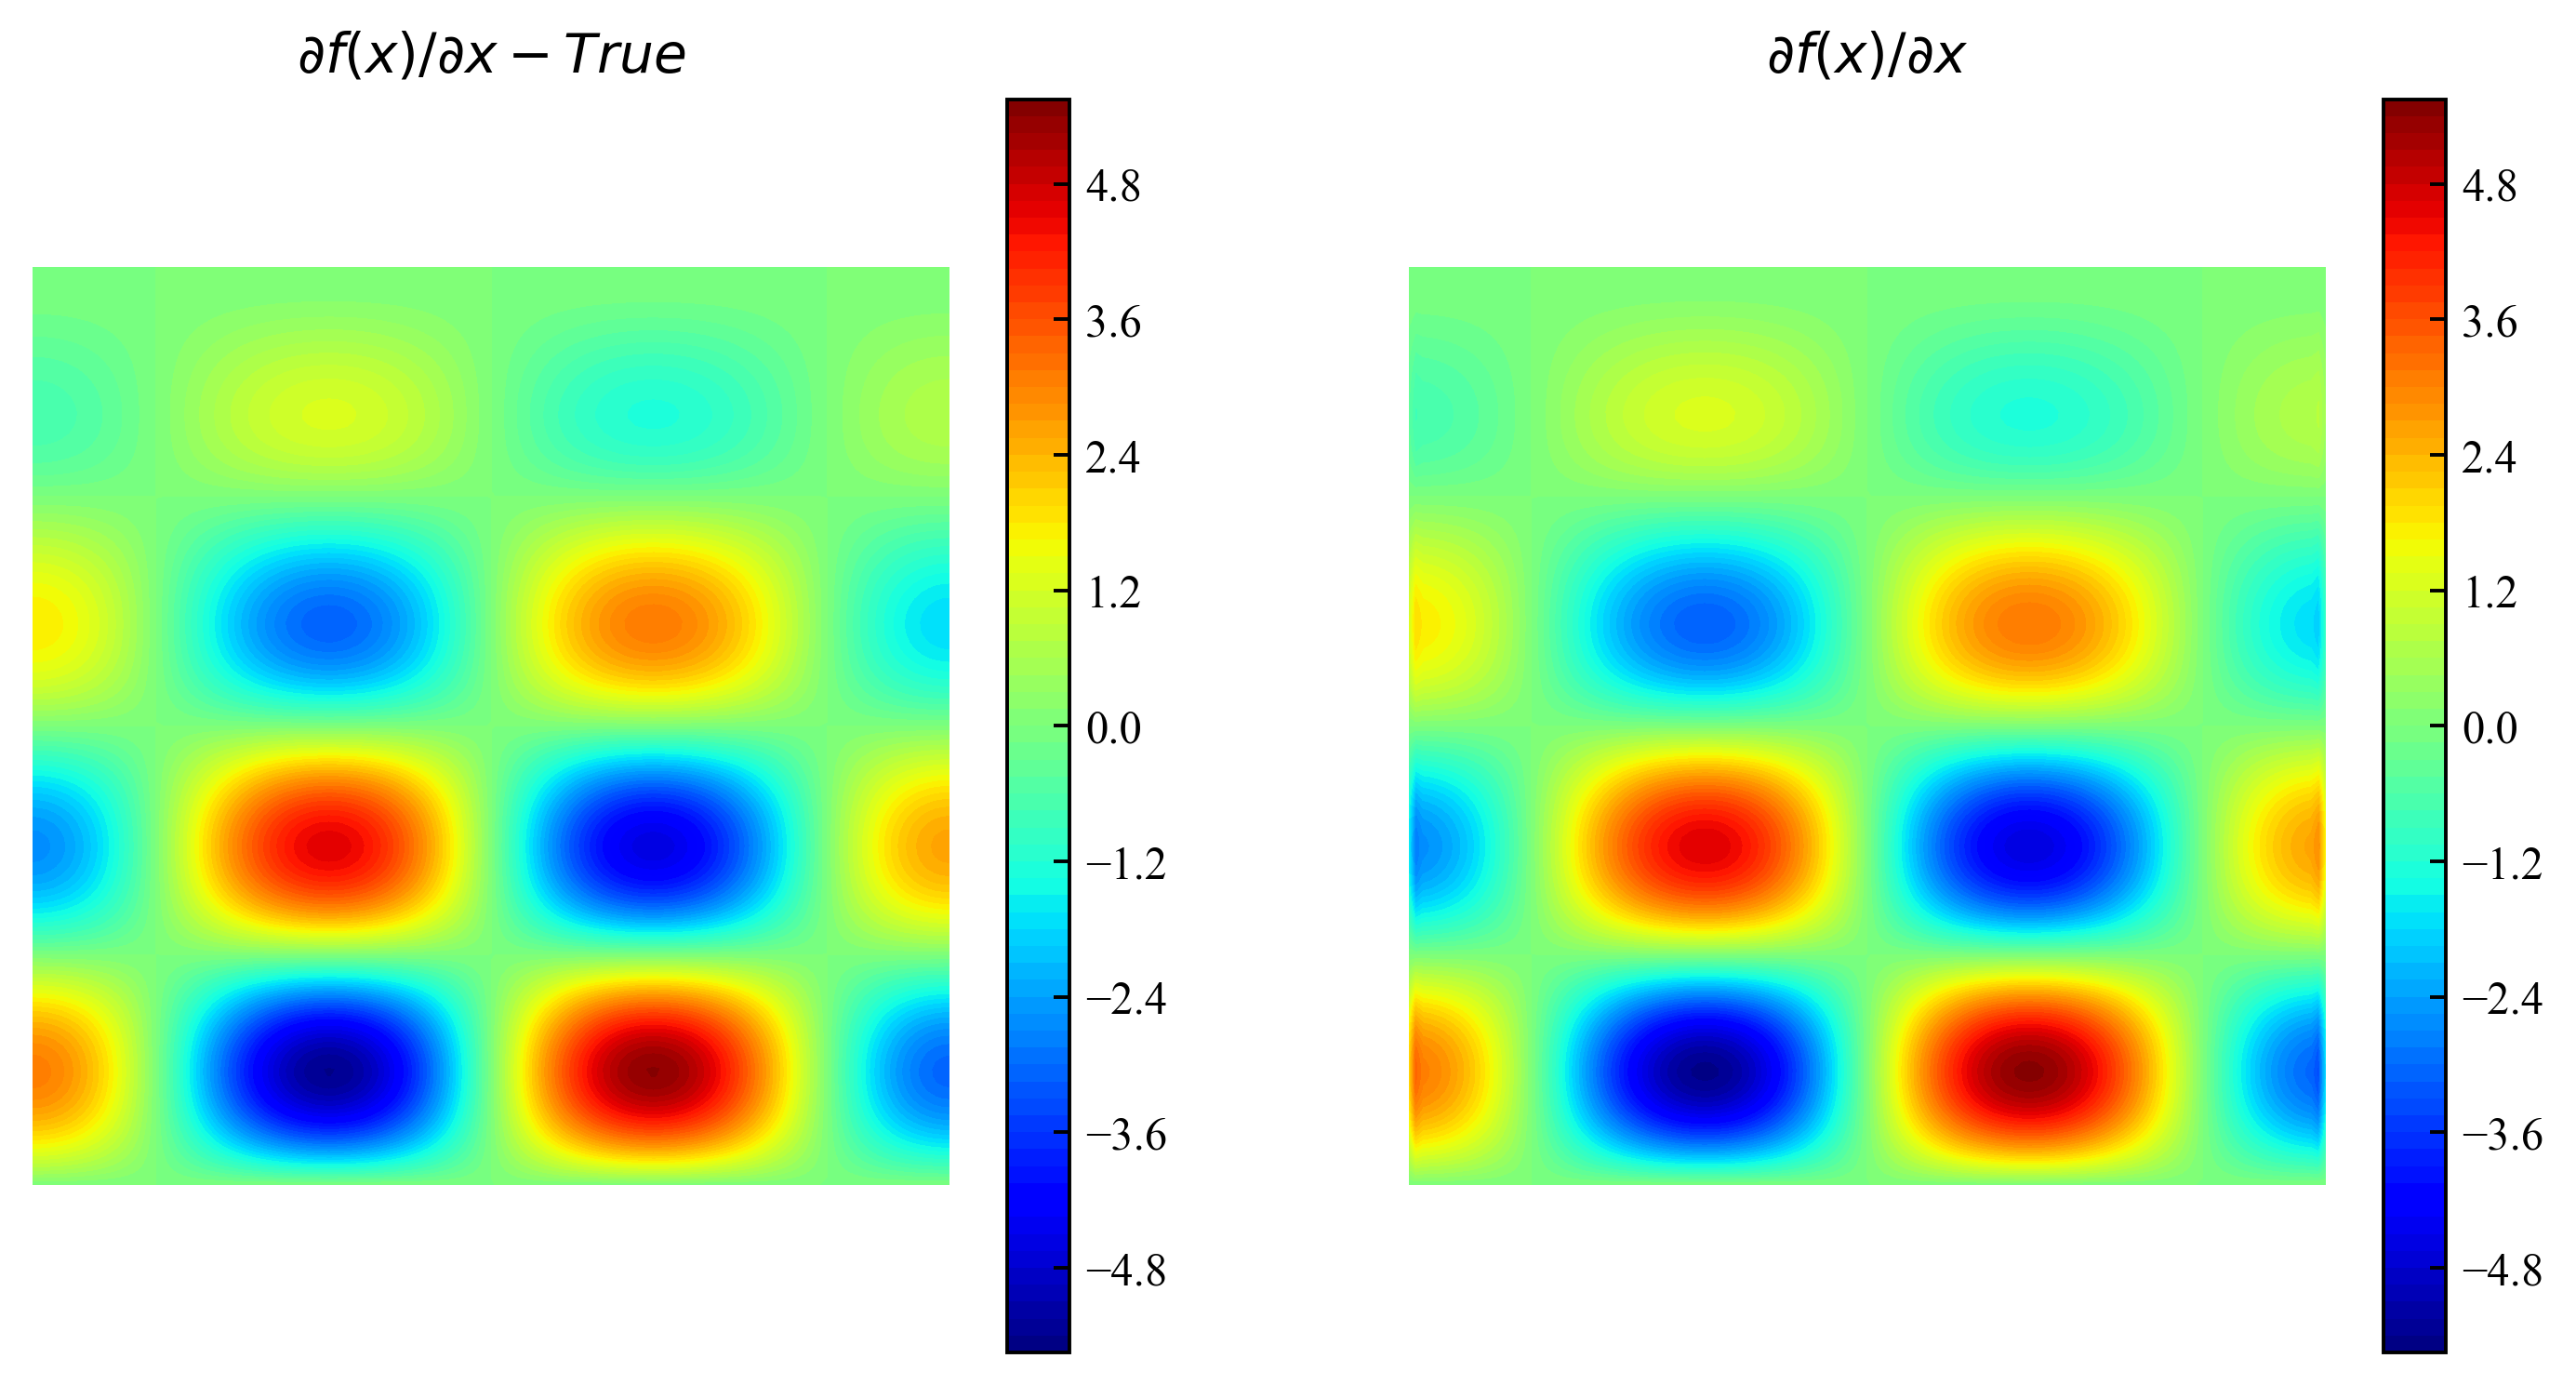

In [15]:
fig, axes = plt.subplots(nrows=1, ncols=2,figsize=(10,5))
ax1 = axes[0].contourf(xGrid, yGrid, dfx, levels=100, cmap=plt.get_cmap('jet'))
axes[0].axis('equal')
axes[0].axis('off')
axes[0].set_title(r'$\partial f(x)/\partial x-True$')
cbar1=fig.colorbar(ax1, ax=axes[0])

ax2 = axes[1].contourf(xGrid, yGrid, f_x, levels=100, cmap=plt.get_cmap('jet'))
axes[1].axis('equal')
axes[1].axis('off')
axes[1].set_title(r'$\partial f(x)/\partial x$')
cbar1=fig.colorbar(ax1, ax=axes[1])


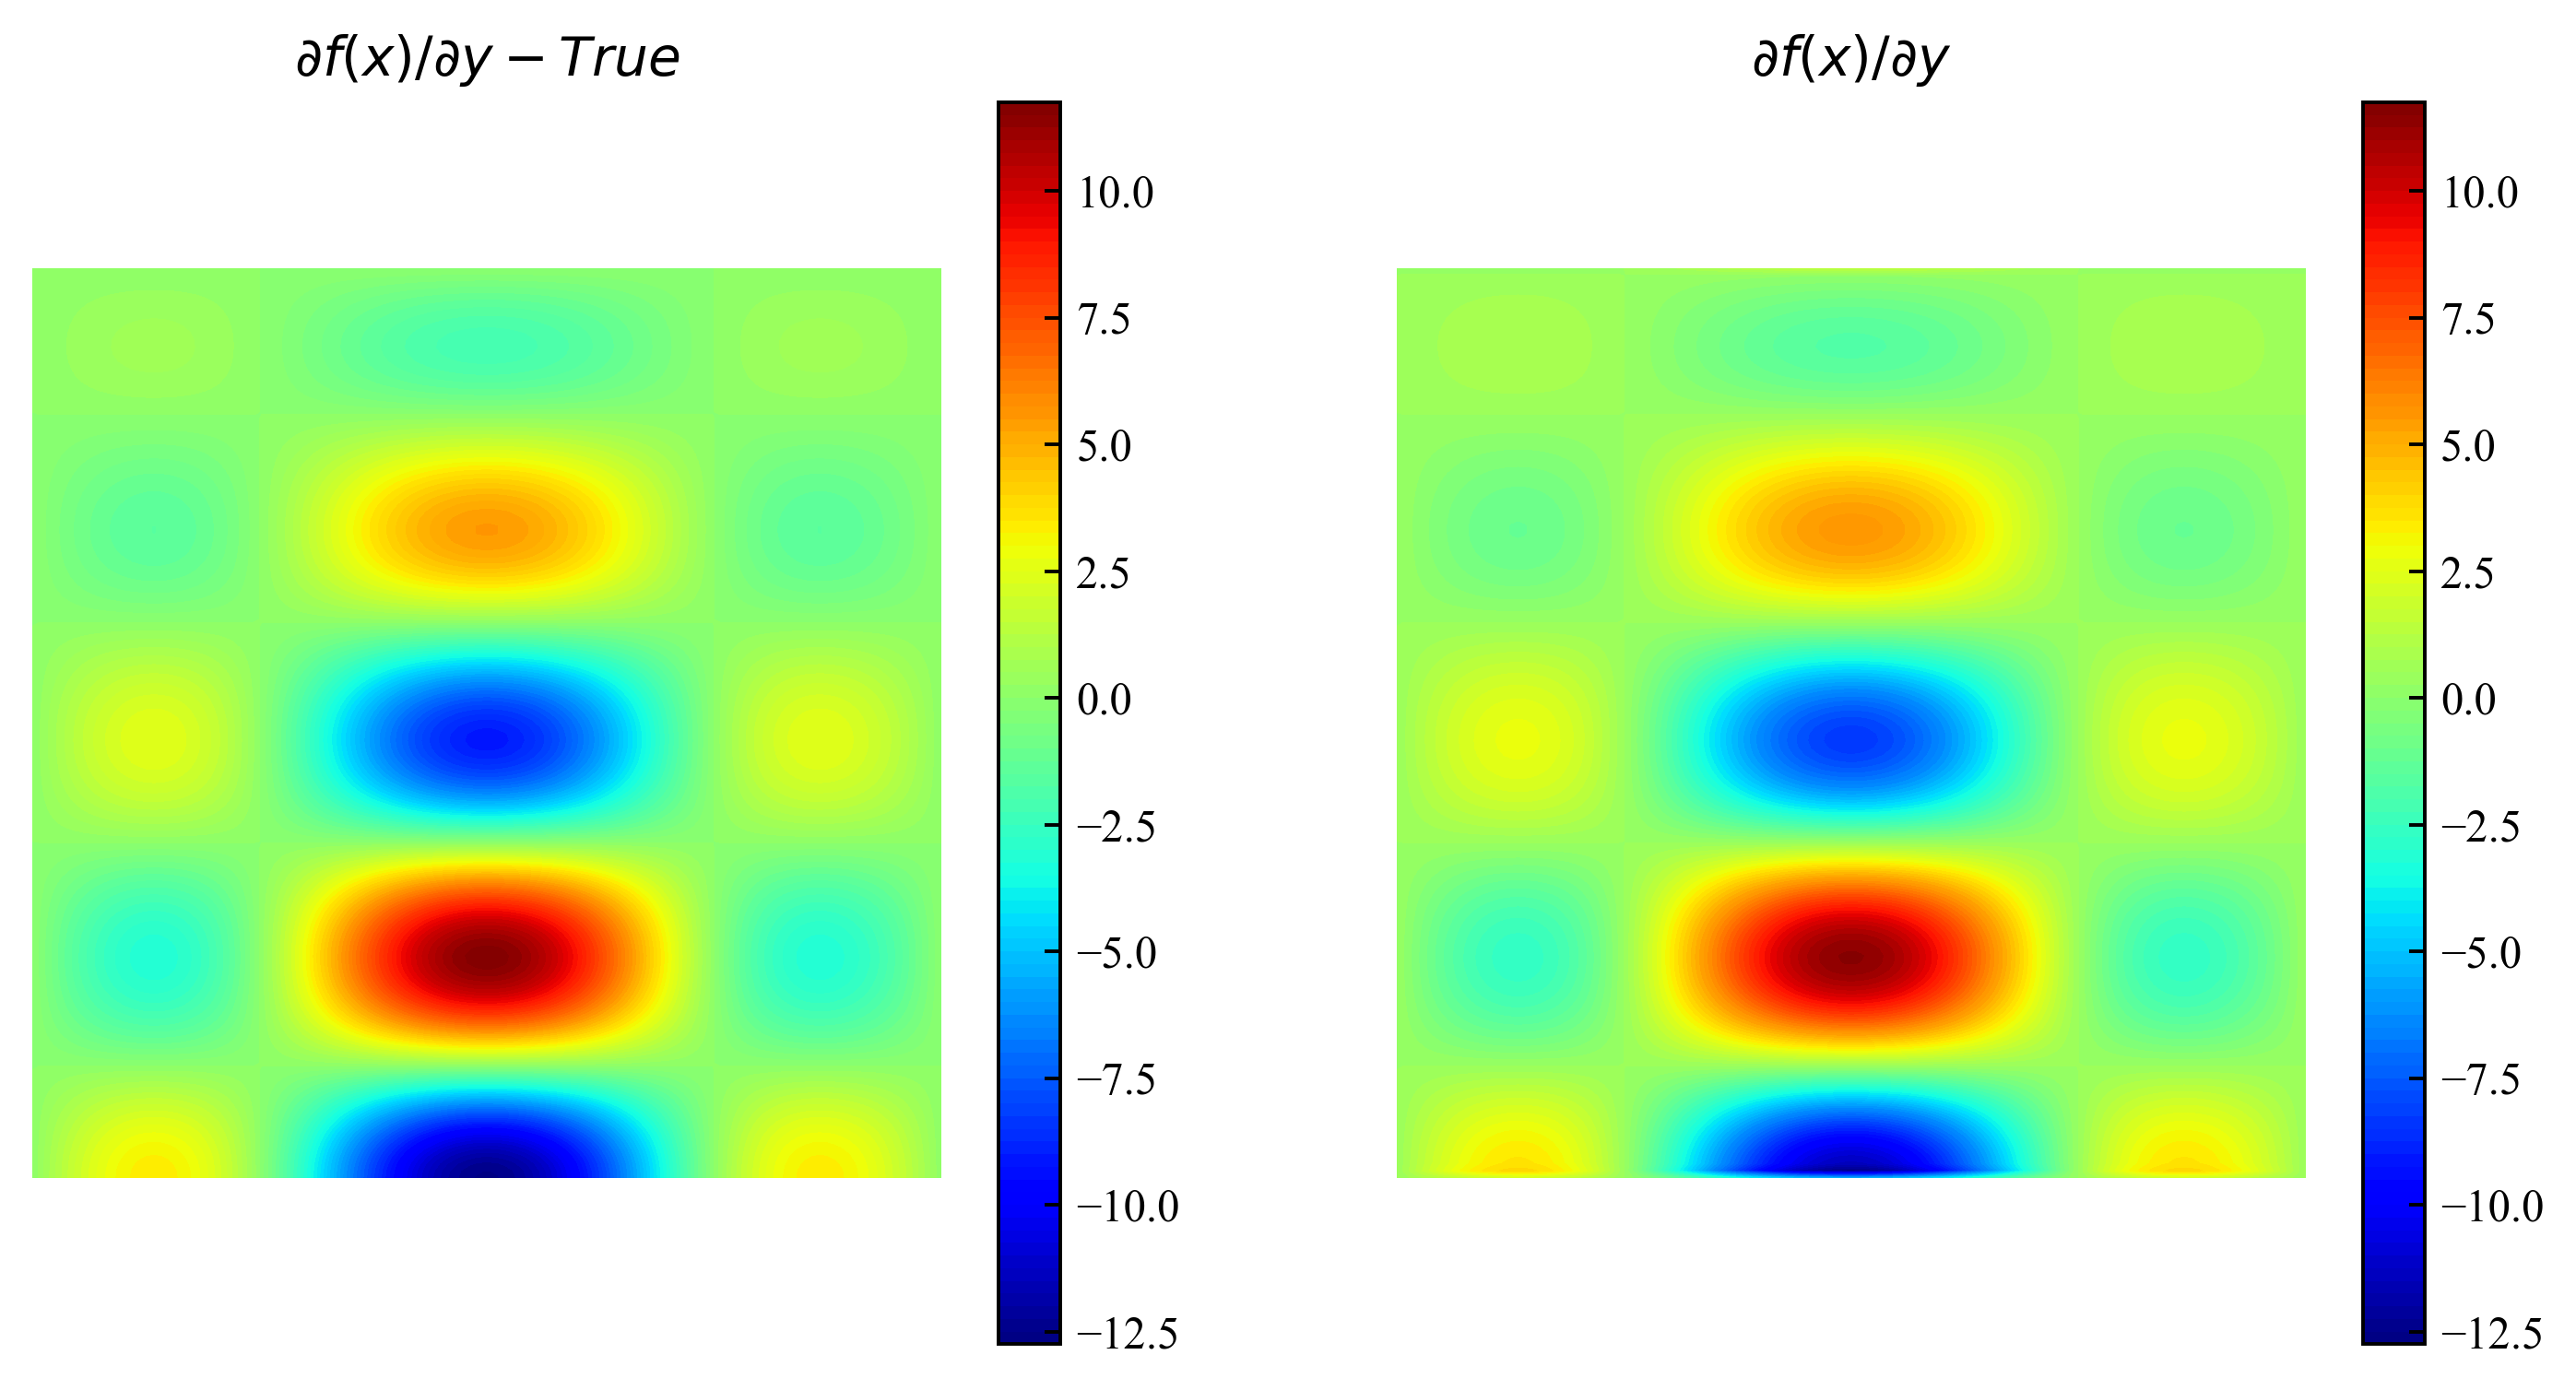

In [16]:
fig, axes = plt.subplots(nrows=1, ncols=2,figsize=(10,5))
ax1 = axes[0].contourf(xGrid, yGrid, dfy, levels=100, cmap=plt.get_cmap('jet'))
axes[0].axis('equal')
axes[0].axis('off')
axes[0].set_title(r'$\partial f(x)/\partial y-True$')
cbar1=fig.colorbar(ax1, ax=axes[0])

ax2 = axes[1].contourf(xGrid, yGrid, f_y, levels=100, cmap=plt.get_cmap('jet'))
axes[1].axis('equal')
axes[1].axis('off')
axes[1].set_title(r'$\partial f(x)/\partial y$')
cbar1=fig.colorbar(ax1, ax=axes[1])